# Customer Churn Prediction for Subscription Services Using Random Forest

**Dataset:** IBM Telco Customer Churn (Kaggle) — 7,043 customers, 21 columns  
**Model:** Random Forest Classifier  
**Task:** Binary classification — will a customer **Churn (Yes)** or **Stay (No)**?

---

## Problem Statement
Subscription businesses lose revenue when customers cancel, and usually only notice after the customer has already left.  
This project uses machine learning to **predict which customers are likely to churn before they leave**, so the company can run targeted retention offers.

## Why Random Forest?
- Churn depends on **combinations** of features (e.g. month-to-month contract + low tenure + no tech support), which a single linear model struggles to capture.
- It builds many decision trees on random subsets of data and averages their votes, which **reduces overfitting**.
- It works with a mix of numerical and categorical features **without needing scaling**.
- It gives **feature importance**, so we can explain *what drives churn*.

## Notebook Workflow
1. Import libraries  
2. Load the data  
3. Explore the data (EDA)  
4. Clean the data  
5. Encode categorical features  
6. Train / test split  
7. Train the Random Forest  
8. Evaluate the model  
9. Feature importance  
10. Per-customer churn risk output  
11. Predict for a single new customer  
12. Save the model (serialization)  
13. Load and reuse the model (reusability)  
14. Conclusion

> **Before running:** keep `WA_Fn-UseC_-Telco-Customer-Churn.csv` in the same folder as this notebook, then use **Kernel → Restart & Run All** (run cells in order, top to bottom).  
> Required libraries: `pandas numpy matplotlib scikit-learn joblib` (and optionally `shap`). `joblib` is installed together with scikit-learn.

## Step 1: Import Libraries
- `pandas`, `numpy` → data handling  
- `matplotlib` → charts  
- `scikit-learn` → splitting data, Random Forest model, and evaluation metrics  
- `shap` → explains *why* the model flagged each customer (optional, used in Step 10)

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

RANDOM_STATE = 42

CSV_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

def find_csv(filename=CSV_FILE, max_depth=3):
    """Look for the CSV in the current folder, its parent, common folders, then sub-folders."""
    home = os.path.expanduser("~")
    cwd = os.getcwd()
    for folder in [cwd, os.path.dirname(cwd), os.path.join(home, "Downloads"),
                   os.path.join(home, "Desktop"), os.path.join(home, "Documents")]:
        path = os.path.join(folder, filename)
        if os.path.exists(path):
            return path
    for root, dirs, files in os.walk(cwd):
        if root[len(cwd):].count(os.sep) >= max_depth:
            dirs[:] = []
        if filename in files:
            return os.path.join(root, filename)
    return None

def load_data():
    path = find_csv()
    if path is None:
        raise FileNotFoundError(
            f"Could not find '{CSV_FILE}'.\n"
            f"Notebook is running from: {os.getcwd()}\n"
            "Fix: copy the CSV into that folder, OR set CSV_FILE above to the full path.")
    print("Using file:", path)
    return pd.read_csv(path)

print("Libraries imported successfully")

Libraries imported successfully


## Step 2: Load the Data
The notebook looks for the CSV in the current folder and gives a clear message if it is missing.

In [2]:
raw_df = load_data()      # untouched copy of the original data
print("Rows:", raw_df.shape[0], "| Columns:", raw_df.shape[1])
raw_df.head()

Using file: /home/claude/nb/WA_Fn-UseC_-Telco-Customer-Churn.csv
Rows: 7043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 3: Explore the Data (EDA)
Before modelling, we check data types, missing values and the balance of the target column.

In [3]:
if 'raw_df' not in globals():
    print("Step 2 was not run - loading the data now.")
    raw_df = load_data()

raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn rate: 26.54%


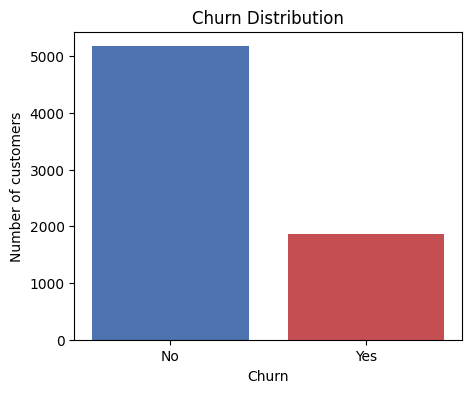

In [4]:
if 'raw_df' not in globals():
    print("Step 2 was not run - loading the data now.")
    raw_df = load_data()

# Churn distribution (is the data balanced?)
churn_counts = raw_df['Churn'].value_counts()
print(churn_counts)
print("\nChurn rate: {:.2%}".format((raw_df['Churn'] == 'Yes').mean()))

plt.figure(figsize=(5, 4))
plt.bar(churn_counts.index, churn_counts.values, color=['#4C72B0', '#C44E52'])
plt.title('Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of customers')
plt.show()

**Observation:** Only about **26.5%** of customers churned, so the data is **imbalanced**.  
A lazy model that always predicts "No" would already get ~73% accuracy — that is why we also check **precision, recall, F1 and ROC-AUC**, and use `class_weight='balanced'` while training.

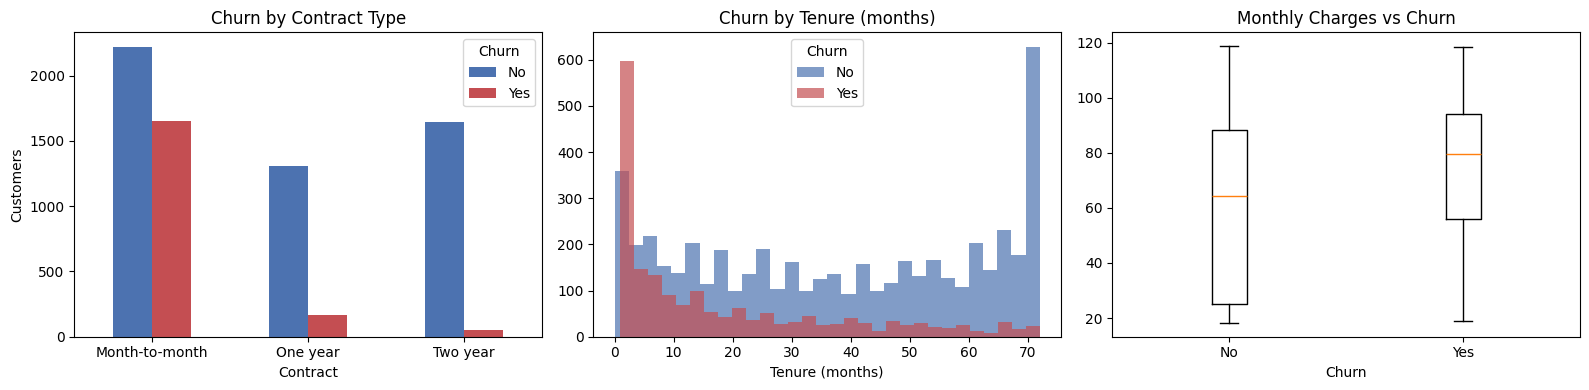

In [5]:
if 'raw_df' not in globals():
    print("Step 2 was not run - loading the data now.")
    raw_df = load_data()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1) Churn by contract type
ct = pd.crosstab(raw_df['Contract'], raw_df['Churn'])
ct.plot(kind='bar', ax=axes[0], color=['#4C72B0', '#C44E52'], rot=0)
axes[0].set_title('Churn by Contract Type')
axes[0].set_ylabel('Customers')

# 2) Tenure distribution by churn
axes[1].hist(raw_df.loc[raw_df['Churn'] == 'No', 'tenure'], bins=30, alpha=0.7, label='No', color='#4C72B0')
axes[1].hist(raw_df.loc[raw_df['Churn'] == 'Yes', 'tenure'], bins=30, alpha=0.7, label='Yes', color='#C44E52')
axes[1].set_title('Churn by Tenure (months)')
axes[1].set_xlabel('Tenure (months)')
axes[1].legend(title='Churn')

# 3) Monthly charges vs churn
axes[2].boxplot([raw_df.loc[raw_df['Churn'] == 'No', 'MonthlyCharges'],
                 raw_df.loc[raw_df['Churn'] == 'Yes', 'MonthlyCharges']],
                labels=['No', 'Yes'])
axes[2].set_title('Monthly Charges vs Churn')
axes[2].set_xlabel('Churn')

plt.tight_layout()
plt.show()

**Observations:**
- Month-to-month customers churn far more than one- or two-year contract customers.
- Churners are concentrated among **new customers** (low tenure).
- Churners tend to pay **higher monthly charges**.

## Step 4: Clean the Data
- `TotalCharges` is stored as text and has **11 blank values** (brand-new customers with 0 tenure) → convert to number and fill with 0.  
- `customerID` is just an identifier with no predictive value → remove it from training (we keep a copy to label the final output).  
- `Churn` is converted from Yes/No to 1/0 because models need numeric targets.

This cell always starts from the untouched copy (`raw_df`), so it is safe to run more than once.

In [6]:
if 'raw_df' not in globals():
    print("Step 2 was not run - loading the data now.")
    raw_df = load_data()

df = raw_df.copy()

# Keep customer IDs for the final output
customer_ids = df['customerID'].copy()

# Fix TotalCharges (blank strings -> NaN -> 0)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Blank TotalCharges found:", int(df['TotalCharges'].isna().sum()))
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Drop ID column
df = df.drop(columns=['customerID'])

# Encode target
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("Missing values remaining:", int(df.isnull().sum().sum()))
df.head()

Blank TotalCharges found: 11
Missing values remaining: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## Step 5: Encode Categorical Features
Machine learning models only understand numbers, so text columns such as `Contract` or `gender` are converted into numeric codes using `LabelEncoder`.  
(Random Forest uses tree splits, so this simple encoding works well and needs no scaling.)

In [7]:
categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
print(f"{len(categorical_cols)} categorical columns:", categorical_cols)

label_encoders = {}          # saved later so new customers can be encoded the same way
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le

df.head()

15 categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


## Step 6: Train / Test Split
We split the data into:
- **80% training set** → the model learns from this
- **20% test set** → hidden from the model; used only to measure real performance

`stratify=y` keeps the same churn rate (~26.5%) in both sets so the test is fair.

In [8]:
X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])
print("Churn rate - Train: {:.2%} | Test: {:.2%}".format(y_train.mean(), y_test.mean()))
print("Number of input features:", X.shape[1])

Train size: 5634 | Test size: 1409
Churn rate - Train: 26.54% | Test: 26.54%
Number of input features: 19


## Step 7: Train the Random Forest
Key settings:
- `n_estimators=200` → builds 200 decision trees  
- `max_depth=10` → limits how deep each tree grows (prevents memorising the training data)  
- `class_weight='balanced'` → gives extra importance to the minority (churn) class  
- `random_state=42` → makes results reproducible

In [9]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf.fit(X_train, y_train)
print("Random Forest trained successfully")

Random Forest trained successfully


## Step 8: Evaluate the Model
The model predicts on the **unseen test set**, and we compare predictions with the real answers.

| Metric | Meaning |
|---|---|
| **Accuracy** | Out of all customers, how many predictions were correct |
| **Precision** | Of those predicted to churn, how many really churned |
| **Recall** | Of those who really churned, how many we caught |
| **F1-Score** | Balance between precision and recall |
| **ROC-AUC** | Overall ability to separate churners from non-churners (1.0 = perfect, 0.5 = random guessing) |

In [10]:
y_pred  = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

metrics = {
    'Accuracy':  accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall':    recall_score(y_test, y_pred),
    'F1-Score':  f1_score(y_test, y_pred),
    'ROC-AUC':   roc_auc_score(y_test, y_proba),
}

for name, value in metrics.items():
    print(f"{name:<10}: {value:.2%}")

Accuracy  : 76.65%
Precision : 54.84%
Recall    : 68.18%
F1-Score  : 60.79%
ROC-AUC   : 83.75%


In [11]:
print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Churned (1)']))

              precision    recall  f1-score   support

Retained (0)       0.87      0.80      0.83      1035
 Churned (1)       0.55      0.68      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.77      0.77      1409



### Confusion Matrix and ROC Curve
The confusion matrix shows exactly where the model is right and wrong:
- **Top-left** → correctly predicted *Retained*  
- **Bottom-right** → correctly predicted *Churned*  
- **Top-right** → false alarms (predicted churn, but customer stayed)  
- **Bottom-left** → missed churners (predicted stay, but customer left)

**Accuracy = (correct predictions) ÷ (total predictions) = (TN + TP) ÷ total**

True Negatives : 825  (correctly predicted Retained)
False Positives: 210  (false alarms)
False Negatives: 119  (missed churners)
True Positives : 255  (correctly predicted Churned)

Accuracy = (825 + 255) / 1409 = 76.65%


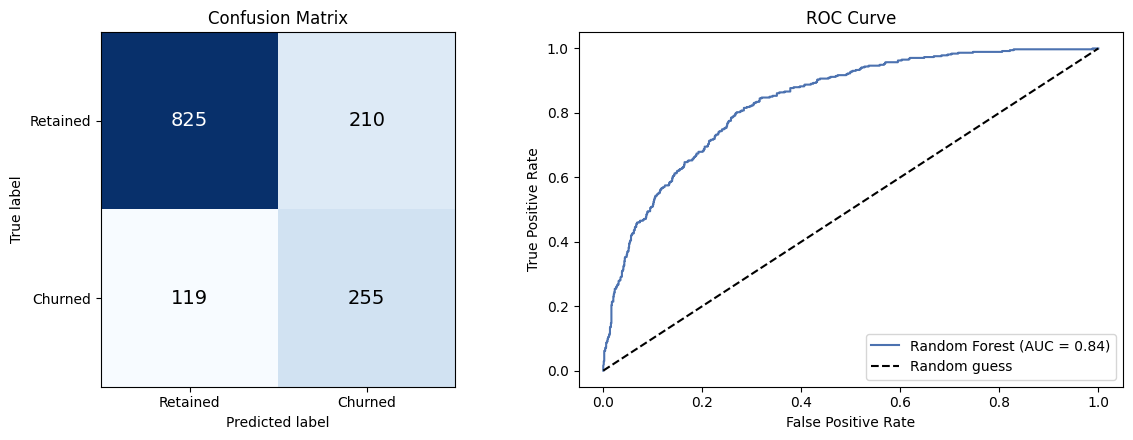

In [12]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives : {tn}  (correctly predicted Retained)")
print(f"False Positives: {fp}  (false alarms)")
print(f"False Negatives: {fn}  (missed churners)")
print(f"True Positives : {tp}  (correctly predicted Churned)")
print(f"\nAccuracy = ({tn} + {tp}) / {len(y_test)} = {(tn + tp) / len(y_test):.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Confusion matrix (drawn manually - works on every matplotlib/sklearn version)
axes[0].imshow(cm, cmap='Blues')
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(['Retained', 'Churned'])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(['Retained', 'Churned'])
axes[0].set_xlabel('Predicted label'); axes[0].set_ylabel('True label')
axes[0].set_title('Confusion Matrix')
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                     color='white' if cm[i, j] > cm.max() / 2 else 'black')

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='#4C72B0', label=f"Random Forest (AUC = {metrics['ROC-AUC']:.2f})")
axes[1].plot([0, 1], [0, 1], 'k--', label='Random guess')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve'); axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

## Step 9: Feature Importance — What Drives Churn?
Random Forest measures how much each feature helps its trees separate churners from non-churners.  
A higher value means the feature matters more for the prediction.

,Feature,Importance
0,Contract,0.165906
1,tenure,0.149895
2,TotalCharges,0.134436
3,MonthlyCharges,0.126135
4,OnlineSecurity,0.084046
5,TechSupport,0.065158
6,InternetService,0.048854
7,PaymentMethod,0.044301
8,OnlineBackup,0.030156
9,PaperlessBilling,0.022793


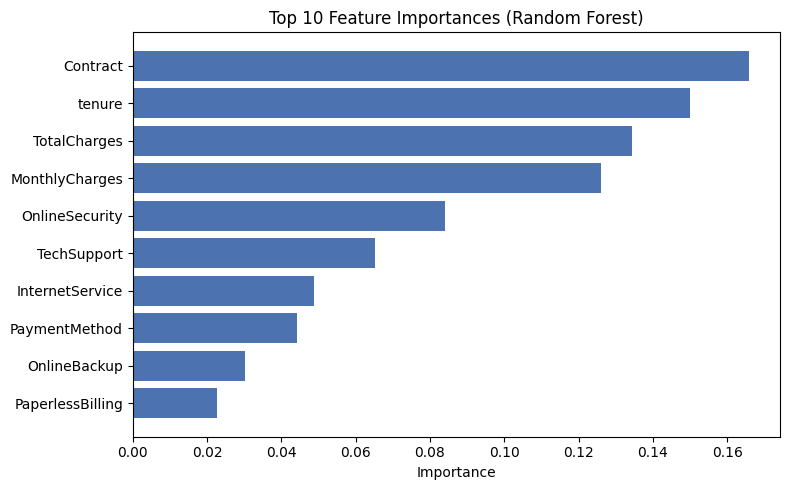

In [13]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

display(feature_importance.head(10))

top10 = feature_importance.head(10)
plt.figure(figsize=(8, 5))
plt.barh(top10['Feature'][::-1], top10['Importance'][::-1], color='#4C72B0')
plt.xlabel('Importance')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.tight_layout()
plt.savefig('model_results.png', dpi=120)
plt.show()

**Insight:** `Contract`, `tenure`, `TotalCharges` and `MonthlyCharges` are the strongest drivers of churn.  
New customers on flexible month-to-month plans, paying higher bills and without support add-ons, are the highest risk group.

## Step 10: Per-Customer Churn Risk Output
Instead of a plain Yes/No, the model gives each customer a **churn probability**, which we convert into a **risk tier**:

| Churn Probability | Risk Tier | Suggested Action |
|---|---|---|
| 0.00 – 0.30 | Low Risk | No action needed |
| 0.30 – 0.60 | Medium Risk | Monitor / soft engagement |
| 0.60 – 1.00 | High Risk | Immediate retention outreach |

We use **SHAP** to find the single biggest reason behind each customer's score. If SHAP is not installed or fails for any reason, the notebook continues with a simpler reason based on overall feature importance (no crash).

In [14]:
def risk_tier(p):
    if p < 0.30:
        return 'Low Risk'
    elif p < 0.60:
        return 'Medium Risk'
    return 'High Risk'

feature_names = X_test.columns.tolist()

def shap_reasons():
    import shap
    explainer = shap.TreeExplainer(rf)
    sv = explainer.shap_values(X_test)
    sv = np.array(sv) if isinstance(sv, list) else sv
    # Handle the different SHAP output shapes across versions -> churn class
    if isinstance(sv, np.ndarray) and sv.ndim == 3:
        sv_churn = sv[1] if sv.shape[0] == 2 else sv[:, :, 1]
    else:
        sv_churn = sv
    reasons = []
    for row in sv_churn:
        idx = int(np.argmax(np.abs(row)))
        direction = 'increases' if row[idx] > 0 else 'decreases'
        reasons.append(f"{feature_names[idx]} ({direction} risk)")
    return reasons

try:
    top_reasons = shap_reasons()
    print("Reasons generated using SHAP")
except Exception as e:
    top_feature = feature_importance.iloc[0]['Feature']
    top_reasons = [f"{top_feature} (most important feature overall)"] * len(X_test)
    print(f"SHAP unavailable ({type(e).__name__}) - using feature-importance fallback. "
          "To enable SHAP run: pip install shap")

risk_df = pd.DataFrame({
    'customerID': customer_ids.loc[X_test.index].values,
    'Churn_Probability': np.round(y_proba, 3),
    'Risk_Tier': [risk_tier(p) for p in y_proba],
    'Top_Reason': top_reasons,
    'Actual_Churn': y_test.map({1: 'Yes', 0: 'No'}).values
}).sort_values('Churn_Probability', ascending=False).reset_index(drop=True)

risk_df.to_csv('customer_risk_predictions.csv', index=False)
print("Saved: customer_risk_predictions.csv  (", len(risk_df), "customers )")
risk_df.head(10)

Reasons generated using SHAP
Saved: customer_risk_predictions.csv  ( 1409 customers )


,customerID,Churn_Probability,Risk_Tier,Top_Reason,Actual_Churn
0,1069-XAIEM,0.963,High Risk,tenure (increases risk),Yes
1,9248-OJYKK,0.954,High Risk,tenure (increases risk),Yes
2,8375-DKEBR,0.947,High Risk,tenure (increases risk),Yes
3,0295-PPHDO,0.946,High Risk,tenure (increases risk),Yes
4,1820-TQVEV,0.945,High Risk,tenure (increases risk),Yes
5,2609-IAICY,0.944,High Risk,tenure (increases risk),Yes
6,9804-ICWBG,0.944,High Risk,tenure (increases risk),Yes
7,5542-TBBWB,0.944,High Risk,tenure (increases risk),No
8,4415-IJZTP,0.937,High Risk,tenure (increases risk),Yes
9,2514-GINMM,0.936,High Risk,tenure (increases risk),Yes


Risk_Tier
Low Risk       747
Medium Risk    295
High Risk      367
Name: count, dtype: int64


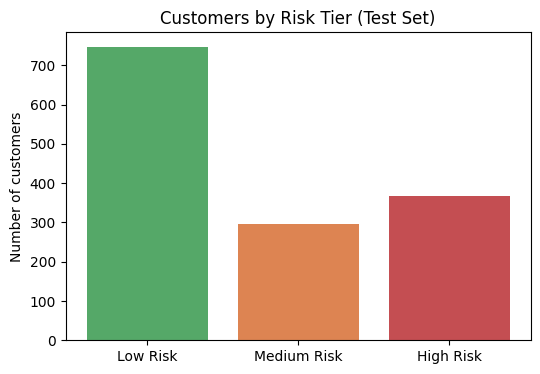

High Risk customers: 367
Of these, actually churned: 60.8%


In [15]:
tier_counts = risk_df['Risk_Tier'].value_counts().reindex(['Low Risk', 'Medium Risk', 'High Risk']).fillna(0)
print(tier_counts.astype(int))

plt.figure(figsize=(6, 4))
plt.bar(tier_counts.index, tier_counts.values, color=['#55A868', '#DD8452', '#C44E52'])
plt.title('Customers by Risk Tier (Test Set)')
plt.ylabel('Number of customers')
plt.show()

# Of the customers flagged High Risk, how many actually churned?
high = risk_df[risk_df['Risk_Tier'] == 'High Risk']
print("High Risk customers:", len(high))
print("Of these, actually churned: {:.1%}".format((high['Actual_Churn'] == 'Yes').mean()))

## Step 11: Predict Churn for a Single New Customer
This shows how the trained model would be used in practice — enter one customer's details and get a churn risk score and recommended action.

In [16]:
# Start from a real customer row, then change the values to experiment
sample = X_test.iloc[[0]].copy()

# Example: a new customer on a month-to-month contract with a high bill
# (Contract encoding: 0 = Month-to-month, 1 = One year, 2 = Two year)
sample['tenure'] = 2
sample['Contract'] = 0
sample['MonthlyCharges'] = 95.0
sample['TotalCharges'] = 190.0

prob = rf.predict_proba(sample)[0, 1]
tier = risk_tier(prob)

actions = {'Low Risk': 'No action needed',
           'Medium Risk': 'Monitor / soft engagement (e.g. check-in email)',
           'High Risk': 'Immediate retention outreach (e.g. discount or plan upgrade)'}

print(f"Churn probability  : {prob:.1%}")
print("Risk tier          :", tier)
print("Recommended action :", actions[tier])

Churn probability  : 55.7%
Risk tier          : Medium Risk
Recommended action : Monitor / soft engagement (e.g. check-in email)


## Step 12: Model Serialization (Saving the Trained Model)

**What is serialization?**  
Training takes time and needs the original data. *Serialization* means saving the trained model to a file on disk, so we can **train once and reuse it any time without retraining**.

**What do we save?**  
Saving only the Random Forest is not enough. To predict for a *new* customer we also need exactly the same preparation that was used during training, so we save everything together in **one bundle file**:

| Item in the bundle | Why it is needed |
|---|---|
| `model` | The trained Random Forest (200 trees) |
| `label_encoders` | Converts text such as `Month-to-month` into the same numbers used in training |
| `feature_columns` | Keeps the 19 input columns in the correct order |
| `risk_thresholds` | The Low / Medium / High cut-offs (0.30 and 0.60) |
| `metadata` | Training date, scikit-learn version, and test metrics, for traceability |

**Tool used:** `joblib` — the standard way to save scikit-learn models (faster and smaller than plain `pickle` for models that contain large NumPy arrays).

> **Notes:** (1) Load the file with the **same scikit-learn version** it was saved with (the version is stored in the metadata). (2) Only load `.joblib` / `.pkl` files from sources you trust, because they can run code when loaded.

In [17]:
import joblib
import sklearn
import datetime

MODEL_FILE = "churn_rf_model.joblib"

model_bundle = {
    "model": rf,
    "label_encoders": label_encoders,
    "feature_columns": X.columns.tolist(),
    "risk_thresholds": {"low": 0.30, "high": 0.60},
    "metadata": {
        "trained_on": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
        "sklearn_version": sklearn.__version__,
        "n_training_rows": int(X_train.shape[0]),
        "metrics": {k: round(float(v), 4) for k, v in metrics.items()},
    },
}

joblib.dump(model_bundle, MODEL_FILE, compress=3)

size_mb = os.path.getsize(MODEL_FILE) / (1024 * 1024)
print(f"Model saved to : {os.path.abspath(MODEL_FILE)}")
print(f"File size      : {size_mb:.2f} MB")
print("Saved metadata :", model_bundle["metadata"])

Model saved to : /home/claude/nb/churn_rf_model.joblib
File size      : 3.74 MB
Saved metadata : {'trained_on': '2026-10-14 05:56', 'sklearn_version': '1.8.0', 'n_training_rows': 5634, 'metrics': {'Accuracy': 0.7665, 'Precision': 0.5484, 'Recall': 0.6818, 'F1-Score': 0.6079, 'ROC-AUC': 0.8375}}


## Step 13: Reusability (Load the Saved Model and Predict Without Retraining)

Now we show that the saved model can be reused **without the training data and without retraining**.

**Part A – Load the file and verify it.** We reload the model from disk and check that it gives *exactly the same* predictions as the model we just trained.  
**Part B – Make the prediction code reusable.** We write a small module, `churn_predictor.py`, with one function `predict_churn()`. It accepts **raw, human-readable values** (like `"Month-to-month"`), prepares them, and returns the churn probability, risk tier and a recommended action. Any other notebook, script or app can simply `import` it.  
**Part C – Use it.** Predict for a single new customer, for several customers at once, and for a whole batch of customers.

### Part A: Load the saved model and verify it

In [18]:
loaded_bundle = joblib.load(MODEL_FILE)
loaded_model = loaded_bundle["model"]

print("Loaded object  :", type(loaded_model).__name__)
print("Metadata       :", loaded_bundle["metadata"])

# The loaded model must behave exactly like the one we trained
same = np.array_equal(loaded_model.predict_proba(X_test), rf.predict_proba(X_test))
print("\nLoaded model gives identical predictions to the trained model:", same)

if loaded_bundle["metadata"]["sklearn_version"] != sklearn.__version__:
    print("WARNING: scikit-learn version differs from when the model was saved.")

Loaded object  : RandomForestClassifier
Metadata       : {'trained_on': '2026-10-14 05:56', 'sklearn_version': '1.8.0', 'n_training_rows': 5634, 'metrics': {'Accuracy': 0.7665, 'Precision': 0.5484, 'Recall': 0.6818, 'F1-Score': 0.6079, 'ROC-AUC': 0.8375}}

Loaded model gives identical predictions to the trained model: True


### Part B: A reusable prediction module (`churn_predictor.py`)
The next cell writes a Python file next to the notebook. It contains everything needed to make predictions from the saved model file.

In [19]:
%%writefile churn_predictor.py
# Reusable churn predictor.
#
# Usage in any script / notebook / app (keep churn_rf_model.joblib in the same folder):
#
#     from churn_predictor import predict_churn
#     result = predict_churn({...19 customer fields...})      # one customer (dict)
#     results = predict_churn(dataframe_of_customers)         # many customers (DataFrame)

import os
import joblib
import numpy as np
import pandas as pd

MODEL_FILE = os.path.join(os.path.dirname(os.path.abspath(__file__)), "churn_rf_model.joblib")

ACTIONS = {
    "Low Risk": "No action needed",
    "Medium Risk": "Monitor / soft engagement (e.g. check-in email)",
    "High Risk": "Immediate retention outreach (e.g. discount or plan upgrade)",
}

_bundle = None   # model is loaded once and then reused (cached)


def load_bundle(model_file=MODEL_FILE):
    global _bundle
    if _bundle is None:
        _bundle = joblib.load(model_file)
    return _bundle


def predict_churn(customer, model_file=MODEL_FILE):
    # Predict churn probability, risk tier and recommended action.
    #   customer : dict (one customer) or DataFrame (many customers) with the 19 raw feature columns
    #   returns  : DataFrame with Churn_Probability, Risk_Tier, Recommended_Action
    bundle = load_bundle(model_file)
    model = bundle["model"]
    encoders = bundle["label_encoders"]
    columns = bundle["feature_columns"]
    th = bundle["risk_thresholds"]

    data = pd.DataFrame([customer]) if isinstance(customer, dict) else customer.copy()

    missing = [c for c in columns if c not in data.columns]
    if missing:
        raise ValueError(f"Missing required fields: {missing}")
    data = data[columns].copy()

    # Same preparation as training: text -> numbers using the SAVED encoders
    for col, enc in encoders.items():
        unknown = set(data[col].astype(str)) - set(enc.classes_)
        if unknown:
            raise ValueError(f"Unknown value(s) {sorted(unknown)} in '{col}'. "
                             f"Allowed values: {list(enc.classes_)}")
        data[col] = enc.transform(data[col].astype(str))
    data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce").fillna(0)

    prob = model.predict_proba(data)[:, 1]
    tier = np.where(prob < th["low"], "Low Risk",
                    np.where(prob < th["high"], "Medium Risk", "High Risk"))

    return pd.DataFrame({
        "Churn_Probability": np.round(prob, 3),
        "Risk_Tier": tier,
        "Recommended_Action": [ACTIONS[t] for t in tier],
    })


Writing churn_predictor.py


### Part C: Use the reusable module

In [20]:
import importlib
import churn_predictor
importlib.reload(churn_predictor)          # makes sure the latest saved version is used
from churn_predictor import predict_churn

# ---- 1) One new customer, entered as plain readable values ----
new_customer = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
    "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes",
    "StreamingMovies": "Yes", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 95.0, "TotalCharges": 190.0,
}

print("Customer 1 (new, month-to-month, high bill, no support):")
display(predict_churn(new_customer))

Customer 1 (new, month-to-month, high bill, no support):


,Churn_Probability,Risk_Tier,Recommended_Action
0,0.9,High Risk,Immediate retention outreach (e.g. discount or...


In [21]:
# ---- 2) Compare with a loyal long-term customer ----
loyal_customer = {
    "gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes",
    "tenure": 60, "PhoneService": "Yes", "MultipleLines": "Yes",
    "InternetService": "DSL", "OnlineSecurity": "Yes", "OnlineBackup": "Yes",
    "DeviceProtection": "Yes", "TechSupport": "Yes", "StreamingTV": "No",
    "StreamingMovies": "No", "Contract": "Two year", "PaperlessBilling": "No",
    "PaymentMethod": "Credit card (automatic)", "MonthlyCharges": 65.0, "TotalCharges": 3900.0,
}

# Several customers at once: pass a DataFrame
two = pd.DataFrame([new_customer, loyal_customer])
out = predict_churn(two)
out.insert(0, "Customer", ["New / at-risk", "Loyal / long-term"])
display(out)

,Customer,Churn_Probability,Risk_Tier,Recommended_Action
0,New / at-risk,0.900,High Risk,Immediate retention outreach (e.g. discount or...
1,Loyal / long-term,0.032,Low Risk,No action needed


In [22]:
# ---- 3) Batch prediction for many customers (e.g. a customer file) ----
# Here we reuse the first 10 rows of the original CSV, but ANY file with the same 19 columns works.
# (Demo only: some of these rows were part of the training data, so this is NOT an accuracy test.)
batch = raw_df.drop(columns=["customerID", "Churn"]).head(10)

batch_result = predict_churn(batch)
batch_result.insert(0, "customerID", raw_df["customerID"].head(10).values)
batch_result["Actual_Churn"] = raw_df["Churn"].head(10).values

batch_result.to_csv("batch_predictions.csv", index=False)
print("Saved: batch_predictions.csv")
display(batch_result)

Saved: batch_predictions.csv


,customerID,Churn_Probability,Risk_Tier,Recommended_Action,Actual_Churn
0,7590-VHVEG,0.571,Medium Risk,Monitor / soft engagement (e.g. check-in email),No
1,5575-GNVDE,0.054,Low Risk,No action needed,No
2,3668-QPYBK,0.738,High Risk,Immediate retention outreach (e.g. discount or...,Yes
3,7795-CFOCW,0.050,Low Risk,No action needed,No
4,9237-HQITU,0.827,High Risk,Immediate retention outreach (e.g. discount or...,Yes
5,9305-CDSKC,0.939,High Risk,Immediate retention outreach (e.g. discount or...,Yes
6,1452-KIOVK,0.604,High Risk,Immediate retention outreach (e.g. discount or...,No
7,6713-OKOMC,0.325,Medium Risk,Monitor / soft engagement (e.g. check-in email),No
8,7892-POOKP,0.774,High Risk,Immediate retention outreach (e.g. discount or...,Yes
9,6388-TABGU,0.052,Low Risk,No action needed,No


In [23]:
# ---- 4) Safety check: the function rejects invalid input with a clear message ----
bad_customer = dict(new_customer, Contract="Weekly")      # "Weekly" was never seen in training
try:
    predict_churn(bad_customer)
except ValueError as e:
    print("Input rejected ->", e)

Input rejected -> Unknown value(s) ['Weekly'] in 'Contract'. Allowed values: ['Month-to-month', 'One year', 'Two year']


### How to reuse the saved model outside this notebook
Keep these **two files** together in one folder: `churn_rf_model.joblib` and `churn_predictor.py`. Then, in any new Python script or notebook:

```python
from churn_predictor import predict_churn

customer = {"gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
            "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
            "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
            "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes",
            "StreamingMovies": "Yes", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
            "PaymentMethod": "Electronic check", "MonthlyCharges": 95.0, "TotalCharges": 190.0}

print(predict_churn(customer))
```

**Why this matters:** the model is trained once, but can be used many times — in a web app, an API, a scheduled batch job, or a dashboard — with no retraining and no access to the original training data.

## Step 14: Conclusion

- A **Random Forest** model was trained on 7,043 telecom subscription customers using 19 input features.
- It correctly classifies roughly **77% of unseen customers** and achieves a **ROC-AUC of about 0.84**, showing a good ability to separate churners from non-churners.
- The strongest churn drivers are **contract type, tenure, and billing charges** — new customers on month-to-month plans with higher bills are most at risk.
- The final output is a **ranked list of customers with churn probability, risk tier and reason**, which a retention team can act on directly.
- The trained model, encoders and settings are **saved as one file** (`churn_rf_model.joblib`) with a reusable `churn_predictor.py` module, so new customers can be scored instantly **without retraining**.

### Limitations & Future Work
- Precision is moderate (~55%) because only ~26% of customers churn, so some loyal customers get flagged as at-risk (false alarms).
- Possible improvements: hyper-parameter tuning, threshold tuning for higher recall, SMOTE oversampling, and testing gradient boosting models such as XGBoost.